# Lab 2: Environmental Simulators

Oliver Grudzinski

One seed (0) for everything. Numbers are saved to `results/`, plots to `figures/`, and the CartPole
video to `videos/`.

In [1]:
%pip install -q "gymnasium[classic-control]" moviepy numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import Video

np.random.seed(0)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## Part 1: Prebuilt Gymnasium environment (CartPole-v1)

Actions are 0 (push left) and 1 (push right). Reward is +1 for every step the pole stays up. An episode
is terminated when the pole tips too far or the cart leaves the track, and truncated at 500 steps. I
count an episode as a success if it reaches the 500 step limit.

### Simple loop

In [3]:
env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)
env.action_space.seed(0)
print("start state:", obs)

for t in range(5):
    a = env.action_space.sample()
    obs, r, terminated, truncated, info = env.step(a)
    print("t =", t, "| action =", a, "| reward =", r, "| state =", obs, "| done =", terminated or truncated)

start state: [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
t = 0 | action = 1 | reward = 1.0 | state = [ 0.01323574  0.17272775 -0.04686959 -0.3551522 ] | done = False
t = 1 | action = 1 | reward = 1.0 | state = [ 0.0166903   0.3684837  -0.05397264 -0.66223824] | done = False
t = 2 | action = 1 | reward = 1.0 | state = [ 0.02405997  0.5643134  -0.0672174  -0.97141534] | done = False
t = 3 | action = 0 | reward = 1.0 | state = [ 0.03534624  0.3701548  -0.08664571 -0.70058215] | done = False
t = 4 | action = 0 | reward = 1.0 | state = [ 0.04274933  0.17633402 -0.10065735 -0.43638363] | done = False


### Video of one random episode

In [4]:
video_env = gym.make("CartPole-v1", render_mode="rgb_array")
video_env = gym.wrappers.RecordVideo(video_env, "videos", name_prefix="cartpole_random")

obs, info = video_env.reset(seed=0)
video_env.action_space.seed(0)
done = False
while not done:
    obs, r, terminated, truncated, info = video_env.step(video_env.action_space.sample())
    done = terminated or truncated
video_env.close()

Video("videos/cartpole_random-episode-0.mp4", embed=True)

C:\Users\grudzinskio\AppData\Roaming\Python\Python313\site-packages\gymnasium\wrappers\rendering.py:293: UserWarning: WARN: Overwriting existing videos at C:\Users\grudzinskio\School Repos\RL-Labs\lab2_environment_simulators\videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(
C:\Users\grudzinskio\AppData\Roaming\Python\Python313\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


### 1000 random episodes

In [5]:
n_episodes = 1000
states = []      # every state visited across all episodes
rewards = []     # rewards[i] is the list of rewards from episode i
lengths = []
successes = []

env.action_space.seed(0)
for ep in range(n_episodes):
    if ep == 0:
        obs, info = env.reset(seed=0)
    else:
        obs, info = env.reset()
    states.append(obs)

    ep_rewards = []
    done = False
    while not done:
        a = env.action_space.sample()
        obs, r, terminated, truncated, info = env.step(a)
        states.append(obs)
        ep_rewards.append(r)
        done = terminated or truncated

    rewards.append(ep_rewards)
    lengths.append(len(ep_rewards))
    # success = hit the 500 step limit instead of the pole falling
    successes.append(truncated and not terminated)

cartpole_episodes = pd.DataFrame({
    "episode": range(n_episodes),
    "length": lengths,
    "total_reward": [sum(r) for r in rewards],
    "success": successes,
})
cartpole_episodes.to_csv("results/cartpole_episodes.csv", index=False)

print("success rate:", np.mean(successes))
print(cartpole_episodes[["length", "total_reward"]].describe())

success rate: 0.0
           length  total_reward
count  1000.00000    1000.00000
mean     22.54600      22.54600
std      12.05152      12.05152
min       8.00000       8.00000
25%      14.00000      14.00000
50%      19.00000      19.00000
75%      27.00000      27.00000
max     102.00000     102.00000


### Summary of the state over all 1000 episodes

In [6]:
state_df = pd.DataFrame(np.array(states),
                        columns=["cart position", "cart velocity", "pole angle", "pole angular velocity"])
state_summary = state_df.describe()
state_summary.to_csv("results/cartpole_state_summary.csv")
state_summary

,cart position,cart velocity,pole angle,pole angular velocity
count,23546.000000,23546.000000,23546.000000,23546.000000
mean,-0.001925,-0.008204,0.001310,0.010564
std,0.092671,0.542389,0.100578,0.825984
min,-0.831609,-2.344525,-0.256423,-3.034608
25%,-0.044972,-0.365213,-0.054577,-0.519169
50%,-0.000772,-0.005504,0.001201,0.008170
75%,0.041565,0.353020,0.058286,0.546958
max,1.201046,2.485445,0.261753,3.162655


### Average reward at each time step

At each time step t, the average is over the episodes that were still running at t. The right plot
shows how many episodes that was.

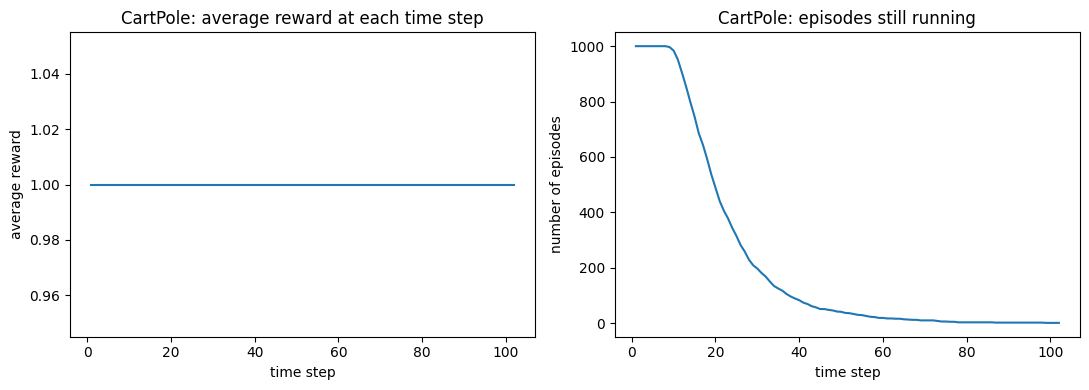

In [7]:
max_len = max(lengths)
avg_reward = np.zeros(max_len)
n_running = np.zeros(max_len, dtype=int)

for t in range(max_len):
    r_at_t = [ep_r[t] for ep_r in rewards if len(ep_r) > t]
    avg_reward[t] = np.mean(r_at_t)
    n_running[t] = len(r_at_t)

steps = np.arange(1, max_len + 1)
pd.DataFrame({"time_step": steps, "avg_reward": avg_reward, "episodes_running": n_running}).to_csv(
    "results/cartpole_reward_by_step.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(steps, avg_reward)
axes[0].set_title("CartPole: average reward at each time step")
axes[0].set_xlabel("time step")
axes[0].set_ylabel("average reward")
axes[1].plot(steps, n_running)
axes[1].set_title("CartPole: episodes still running")
axes[1].set_xlabel("time step")
axes[1].set_ylabel("number of episodes")
fig.tight_layout()
fig.savefig("figures/cartpole_reward_by_step.png", dpi=150)
plt.show()

## Part 2: Custom environments

Both follow the same layout as the Corridor example in the lab handout: `__init__`, `reset`, and a
`step` that returns a dict with the new state, the reward, and whether the episode is done. I added a
`success` flag to that dict so the runs can count wins.

Rewards for both: -1 per step, +100 for winning (finish line / base), -100 for losing (crash / caught).

### Environment 1: Racetrack

The grid is 25 cells wide and 30 tall with y = 0 at the bottom. The vertical section is x = 0..9 for
all 30 rows, and the horizontal section is x = 10..24 in the top 10 rows (y = 20..29). The start line is
the row y = 0 and the finish line is the column x = 24.

In [8]:
class Racetrack:

    def __init__(self):
        self.width = 25
        self.height = 30
        # 9 actions: change (vx, vy) by -1, 0 or +1 each
        self.action_space = [(ax, ay) for ax in (-1, 0, 1) for ay in (-1, 0, 1)]
        # state = (x, y, vx, vy), x and y only take on-track cells
        self.state_space = {'x': range(0, 25), 'y': range(0, 30), 'vx': range(-4, 5), 'vy': range(0, 5)}
        self.x, self.y, self.vx, self.vy = 0, 0, 0, 0

    def on_track(self, x, y):
        in_vertical = 0 <= x <= 9 and 0 <= y <= 29
        in_horizontal = 10 <= x <= 24 and 20 <= y <= 29
        return in_vertical or in_horizontal

    def reset(self, seed=None):
        # only reseed when asked, otherwise every episode would get a fresh random seed
        if seed is not None:
            np.random.seed(seed)
        self.x = np.random.randint(0, 10)   # random cell on the start line
        self.y = 0
        self.vx, self.vy = 0, 0
        return [self.x, self.y, self.vx, self.vy]

    def step(self, action):
        ax, ay = self.action_space[action]
        # speeds are "less than 5"; only the vertical one has to be nonnegative
        vx = int(np.clip(self.vx + ax, -4, 4))
        vy = int(np.clip(self.vy + ay, 0, 4))
        # both can't be 0 off the start line, so the change is ignored
        if vx == 0 and vy == 0 and self.y != 0:
            vx, vy = self.vx, self.vy
        self.vx, self.vy = vx, vy

        # check the cells along the move, not just where it lands, so the car can't jump the corner
        n_points = max(abs(vx), abs(vy))
        for i in range(1, n_points + 1):
            cx = self.x + round(i * vx / n_points)
            cy = self.y + round(i * vy / n_points)
            if cx >= 24 and 20 <= cy <= 29:
                self.x, self.y = 24, cy
                return {'state': [self.x, self.y, vx, vy], 'r': 100, 'done': True, 'success': True}
            if not self.on_track(cx, cy):
                # crashed into the boundary (anywhere but the finish line)
                return {'state': [self.x, self.y, vx, vy], 'r': -100, 'done': True, 'success': False}

        self.x += vx
        self.y += vy
        return {'state': [self.x, self.y, vx, vy], 'r': -1, 'done': False, 'success': False}

### Environment 2: Chase

Field size n = 20. The player starts at (0, 0), the base is at (20, 20), and the predator starts
somewhere uniformly random in the field.

In [9]:
class Chase:

    def __init__(self, config):
        self.n = config['n']
        self.base = np.array([self.n, self.n], dtype=float)
        # 9 actions: change (vx, vy) by -1, 0 or +1 each (stochastic size)
        self.action_space = [(ax, ay) for ax in (-1, 0, 1) for ay in (-1, 0, 1)]
        # state = (player x, player y, vx, vy, predator x, predator y), all continuous (low, high)
        self.state_space = {'player x': (0, self.n), 'player y': (0, self.n),
                            'vx': (-5, 5), 'vy': (-5, 5),
                            'predator x': (0, self.n), 'predator y': (0, self.n)}
        self.player = np.zeros(2)
        self.vel = np.zeros(2)
        self.predator = np.zeros(2)

    def get_state(self):
        return [self.player[0], self.player[1], self.vel[0], self.vel[1],
                self.predator[0], self.predator[1]]

    def reset(self, seed=None):
        if seed is not None:
            np.random.seed(seed)
        self.player = np.array([0.0, 0.0])
        self.vel = np.array([0.0, 0.0])
        self.predator = np.random.uniform(0, self.n, size=2)
        return self.get_state()

    def move_player(self):
        self.player = np.clip(self.player + self.vel, 0, self.n)   # stay in the field
        return np.linalg.norm(self.player - self.base) <= 0.5      # escaped?

    def move_predator(self):
        gap = self.player - self.predator
        dist = np.linalg.norm(gap)
        if dist <= 4:
            # close enough to land right on the player
            self.predator = self.player.copy()
            return True
        self.predator = self.predator + 4 * gap / dist
        return False

    def step(self, action):
        a = self.action_space[action]
        for i in range(2):
            if a[i] == 1:
                self.vel[i] += np.random.uniform(0.5, 1.5)
            elif a[i] == -1:
                self.vel[i] -= np.random.uniform(0.5, 1.5)
        self.vel = np.clip(self.vel, -5, 5)

        caught = False
        escaped = False
        if np.random.rand() < 0.5:
            # predator moves first
            caught = self.move_predator()
            if not caught:
                escaped = self.move_player()
        else:
            escaped = self.move_player()
            if not escaped:
                caught = self.move_predator()

        if escaped:
            r = 100
        elif caught:
            r = -100
        else:
            r = -1
        return {'state': self.get_state(), 'r': r, 'done': caught or escaped, 'success': escaped}

### Random actions, 1000 episodes each

Positions are logged every time the agent picks an action, so the heatmaps show where it spent its
time steps.

In [10]:
def run_random(env, n_episodes=1000, seed=0):
    positions = []
    rows = []
    for ep in range(n_episodes):
        if ep == 0:
            state = env.reset(seed=seed)
        else:
            state = env.reset()
        total_reward = 0
        steps = 0
        done = False
        while not done:
            positions.append(state[:2])
            a = np.random.randint(len(env.action_space))
            out = env.step(a)
            state = out['state']
            total_reward += out['r']
            steps += 1
            done = out['done']
        rows.append({'episode': ep, 'length': steps, 'total_reward': total_reward, 'success': out['success']})
    return pd.DataFrame(rows), np.array(positions)

In [11]:
track = Racetrack()
race_df, race_pos = run_random(track)
race_df.to_csv("results/racetrack_episodes.csv", index=False)

chase = Chase({'n': 20})
chase_df, chase_pos = run_random(chase)
chase_df.to_csv("results/chase_episodes.csv", index=False)

print("Racetrack success rate (crossed the finish line):", race_df['success'].mean())
print("Chase success rate (reached base):", chase_df['success'].mean())

Racetrack success rate (crossed the finish line): 0.003
Chase success rate (reached base): 0.0


### Heatmaps

Log scale, because the start cells get visited far more than anything else.

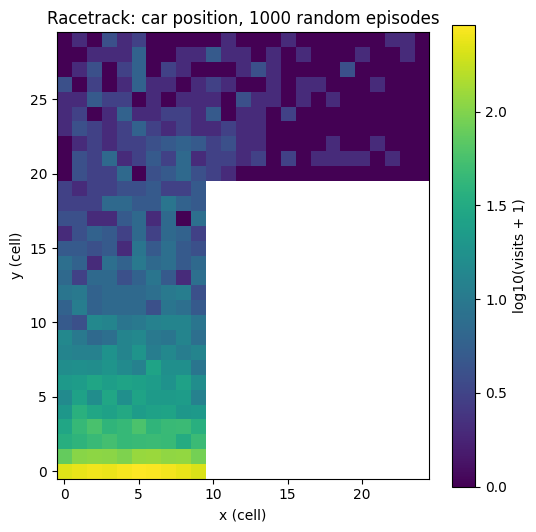

In [12]:
race_counts = np.zeros((track.height, track.width))
for x, y in race_pos:
    race_counts[int(y), int(x)] += 1
pd.DataFrame(race_counts).to_csv("results/racetrack_heatmap.csv")

# blank out the cells that aren't part of the track
race_plot = np.log10(race_counts + 1)
for y in range(track.height):
    for x in range(track.width):
        if not track.on_track(x, y):
            race_plot[y, x] = np.nan

plt.figure(figsize=(6, 6))
plt.imshow(race_plot, origin="lower", cmap="viridis")
plt.colorbar(label="log10(visits + 1)")
plt.title("Racetrack: car position, 1000 random episodes")
plt.xlabel("x (cell)")
plt.ylabel("y (cell)")
plt.savefig("figures/racetrack_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

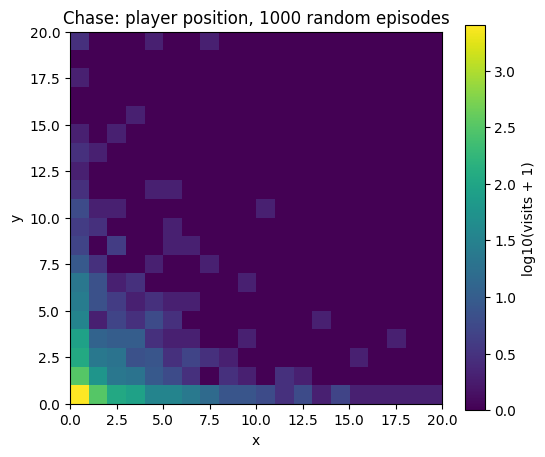

In [13]:
n = chase.n
chase_counts, _, _ = np.histogram2d(chase_pos[:, 0], chase_pos[:, 1], bins=n, range=[[0, n], [0, n]])
pd.DataFrame(chase_counts.T).to_csv("results/chase_heatmap.csv")   # rows = y, columns = x

plt.figure(figsize=(6, 5))
# histogram2d gives [x, y], imshow wants [row = y, column = x]
plt.imshow(np.log10(chase_counts.T + 1), origin="lower", extent=[0, n, 0, n], cmap="viridis")
plt.colorbar(label="log10(visits + 1)")
plt.title("Chase: player position, 1000 random episodes")
plt.xlabel("x")
plt.ylabel("y")
plt.savefig("figures/chase_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Part 3: Make learning tough

`ObstacleRacetrack` is the same racetrack, but every reset drops 40 blocked cells at random spots on the
track (never on the start row or the finish column). Driving into a blocked cell counts as a crash, same
as hitting the wall.

In [14]:
class ObstacleRacetrack(Racetrack):

    def __init__(self, n_obstacles):
        super().__init__()
        self.n_obstacles = n_obstacles
        self.obstacles = set()

    def reset(self, seed=None):
        state = super().reset(seed)
        # new obstacles every episode
        free_cells = []
        for x in range(self.width - 1):          # skip the finish column
            for y in range(1, self.height):      # skip the start row
                if Racetrack.on_track(self, x, y):
                    free_cells.append((x, y))
        picks = np.random.choice(len(free_cells), self.n_obstacles, replace=False)
        self.obstacles = set(free_cells[i] for i in picks)
        return state

    def on_track(self, x, y):
        return Racetrack.on_track(self, x, y) and (x, y) not in self.obstacles

In [15]:
hard_track = ObstacleRacetrack(n_obstacles=40)
hard_df, hard_pos = run_random(hard_track)
hard_df.to_csv("results/obstacle_racetrack_episodes.csv", index=False)

comparison = pd.DataFrame({
    'environment': ['Racetrack', 'Racetrack + obstacles'],
    'success rate': [race_df['success'].mean(), hard_df['success'].mean()],
    'average episode reward': [race_df['total_reward'].mean(), hard_df['total_reward'].mean()],
    'average episode length': [race_df['length'].mean(), hard_df['length'].mean()],
})
comparison.to_csv("results/racetrack_comparison.csv", index=False)
comparison

,environment,success rate,average episode reward,average episode length
0,Racetrack,0.003,-104.648,6.248
1,Racetrack + obstacles,0.000,-103.694,4.694
